# 第十二轮：联合学习球员残差状态

本轮固定原2,588场2023比赛和0.5阈值，比较同一强历史特征模型的三种结构：
无玩家残差、静态玩家残差、随季度变化的玩家残差。本轮没有候选达到1,812场正确，70%目标继续保持active。
正式分支推荐 **previous_probability_recommendation**：**1696/2,588 = 65.533%**，
log loss **0.609407**。全部2023结果仍是重复查看后的探索性证据；2024–2025继续封存。

## 完整队列对比

| model | information_regime | correct | accuracy | mean_log_loss | additional_correct_for_70 |
| --- | --- | --- | --- | --- | --- |
| rank_reference | 原T−21历史输入 | 1640 | 0.633694 | 0.629796 | 172 |
| overall_elo_stale | 原T−21历史输入 | 1640 | 0.633694 | 0.639146 | 172 |
| previous_probability_recommendation | 原T−21历史输入 | 1696 | 0.655332 | 0.609407 | 116 |
| shared_only | 原T−21历史输入 | 1706 | 0.659196 | 0.606453 | 106 |
| shared_static_residual | 原T−21历史输入 | 1711 | 0.661128 | 0.608872 | 101 |
| shared_dynamic_residual | 原T−21历史输入 | 1692 | 0.653787 | 0.611061 | 120 |
| previous_round5_exploration | 原T−21历史输入 | 1715 | 0.662674 | 0.609871 | 97 |
| market_lambda1 | 历史输入；训练期市场监督 | 1712 | 0.661515 | 0.604599 | 100 |
| history_linear_C0.03_alpha1 | 当前开盘价＋T−21历史修正；缺失回退R4 | 1760 | 0.680062 | 0.596723 | 52 |
| raw_market | 当前末盘价优先；缺失用开盘或R4回退 | 1752 | 0.676971 | 0.587691 | 60 |

![第十二轮模型比较](results/round12/round12_comparison.png)

市场上下文保留原信息条件，不能与本轮纯历史模型混称同一输入条件。
此前1,760场正确的opening+history行没有被开发期选择，不能按2023最好分数直接推荐。

## 选择与机制检验

2020–2021选择 **shared_static_residual**；其2022相对R4净正确变化
**+4/2,528**，预先门槛为至少+13且loss增加不超过.005。
因此gate为 **retain_round4**。独立记录的2020–2022 pooled选择
**shared_dynamic_residual** 在2023为 **1692/2,588**、
loss **0.611061**。没有根据2023重选残差方差、阈值或混合权重。

| candidate | control | oof_net_correct | oof_loss_change | validation_net_correct | validation_loss_change |
| --- | --- | --- | --- | --- | --- |
| shared_static_residual | shared_only | 3 | 0.001680 | 5 | 0.002419 |
| shared_dynamic_residual | shared_static_residual | 10 | 0.002058 | -19 | 0.002189 |
| shared_dynamic_residual | shared_only | 13 | 0.003738 | -14 | 0.004607 |

static−shared检验稳定玩家残差是否增益；dynamic−static检验时间耦合是否有额外价值。
完整前推年度结果见[temporal_cv.csv](results/round12/residual_state/temporal_cv.csv)，配对日期块区间见
[summary.json](results/round12/residual_state/summary.json)。这些区间以拟合后的预测为条件，没有校正
多轮搜索或全部跨日期球员依赖。不能把训练拟合更好直接解释为预测更好。

静态模型相对原共享控制纠正59场、弄错54场，净增5；动态模型纠正73场、弄错87场。
两种状态扩展相对同输入控制在2020、2021、2022、2023每年的log loss都更差。
这说明本次固定先验和季度近似没有提供稳定的概率收益，并不否定所有二元BT或动态模型。

| model | mean_absolute_state_logit | rms_state_logit | classifications_changed_by_state |
| --- | --- | --- | --- |
| shared_static_residual | 0.183669 | 0.236364 | 173 |
| shared_dynamic_residual | 0.265693 | 0.340760 | 258 |

状态贡献并非全被压成零。表中分类变化是相对各扩展模型**自身联合拟合beta的共享部分**，
不是相对独立R5控制；beta也会因联合拟合而改变，因此不能把全部增减归因于状态项的单独因果作用。

## 方法与时间边界

精确复用R5 `all_inputs_spline_C0.01`：199个输入、256维设计、C=.01、三年样本权重。
每个outer年只在原21天purge后的历史上拟合变换和共享beta。静态或季度状态与beta
共同优化最终比赛二元似然；之后每个目标日期只在T−21以内的历史前缀重新求状态。
beta、缩放、样条和先验均冻结。允许前缀内部的历史状态平滑，不能称严格单向filter。

初始残差SD=.35、年度创新SD=.15均是预先固定的实用log-odds尺度，非论文验证过的ATP参数。
未出现的季度不建自由节点；预测取最后可用状态。没有合规历史的玩家残差为0；
全球训练未见但后来已有可用比赛的玩家能够获得状态。历史从有完整冻结特征的2009年开始。
未引入市场、新完赛日期或逐分charting数据。

实际有 **12次global优化、256次状态优化**，
不是只训练三个模型一次。每个年度的模型和各截止日状态都已保存。旧强控制的全部
6,130条OOF与2,588条2023概率须误差≤1e−10且分类完全一致才会继续。

## 复跑和独立核验

在已复建前五轮输入和当前依赖的环境中运行到新目录：

```bash
.venv/bin/python -m scripts.train_residual_state_round12 --output /tmp/atp-round12-reproduction --approved-protocol-sha256 54fbc7f95d8419cde22d0d26a1f14d5f6e01acd748a72f73959f365dacc45e34
.venv/bin/python -m scripts.audit_residual_state_round12
.venv/bin/python -m scripts.report_round12
```

第一条创建独立复跑产物；后两条默认核验和呈现仓库原冻结运行，不会自动切到复跑目录。
原路径已有产物时runner拒绝覆盖。模型权重在residual_state/model_2020.joblib至
model_2023.joblib以及frozen_models.joblib，本地保留且由运行清单绑定哈希，可按命令重建。
已保存截止日的推断用`--predict-features`与`--query-metadata`，query必须不含a_won；
新截止日需要按同一边界提供合规历史并调用引擎的predict_asof，不能冒用旧状态。

[artifact_audit.json](results/round12/residual_state/artifact_audit.json)记录独立检查范围与局限；
[verification.json](results/round12/verification.json)记录常规测试。重载状态复算不等于重新运行全部优化器，
也不等于独立重建326列历史特征或重新裁定每个原始结果。

低级别市场监督方向先完成了[可行性审查](docs/research/round12_market_transfer_feasibility.md)，
严格筛选留下29,050行，但有比分截断、短比赛偏差和缺少新排序信号的问题，因此没有拟合。
这不是把辅助数据数量当成准确率提升。核方法、排名轨迹、身高和左右手重复路线也已排除。

[执行协议](docs/research/round12_residual_state_protocol.md) ·
[一手文献与负证据](docs/research/round12_residual_state_proposal.md) ·
[独立结果解释](docs/research/round12_residual_state_findings.md) ·
[探索决策记录](docs/research/round12_decisions.md)


In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
root=Path.cwd()
display(pd.read_csv(root/'results/round12/overview_comparison.csv'))

,model,recommended,matches,correct,accuracy,mean_log_loss,brier,branch,information_regime,additional_correct_for_70
0,rank_reference,False,2588,1640,0.633694,0.629796,0.220156,residual_state,原T−21历史输入,172
1,overall_elo_stale,NaN,2588,1640,0.633694,0.639146,0.223312,freshness,原T−21历史输入,172
2,previous_probability_recommendation,True,2588,1696,0.655332,0.609407,0.211493,residual_state,原T−21历史输入,116
3,shared_only,False,2588,1706,0.659196,0.606453,0.210323,residual_state,原T−21历史输入,106
4,shared_static_residual,False,2588,1711,0.661128,0.608872,0.211238,residual_state,原T−21历史输入,101
5,shared_dynamic_residual,False,2588,1692,0.653787,0.611061,0.212016,residual_state,原T−21历史输入,120
6,previous_round5_exploration,False,2588,1715,0.662674,0.609871,0.211658,residual_state,原T−21历史输入,97
7,market_lambda1,NaN,2588,1712,0.661515,0.604599,0.209549,prior,历史输入；训练期市场监督,100
8,history_linear_C0.03_alpha1,NaN,2588,1760,0.680062,0.596723,0.206387,prior,当前开盘价＋T−21历史修正；缺失回退R4,52
9,raw_market,NaN,2588,1752,0.676971,0.587691,0.202766,prior,当前末盘价优先；缺失用开盘或R4回退,60


In [2]:
display(pd.read_csv(root/'results/round12/residual_state/matched_controls.csv'))

,candidate,control,oof_net_correct,oof_loss_change,validation_net_correct,validation_loss_change
0,shared_static_residual,shared_only,3,0.001680,5,0.002419
1,shared_dynamic_residual,shared_static_residual,10,0.002058,-19,0.002189
2,shared_dynamic_residual,shared_only,13,0.003738,-14,0.004607


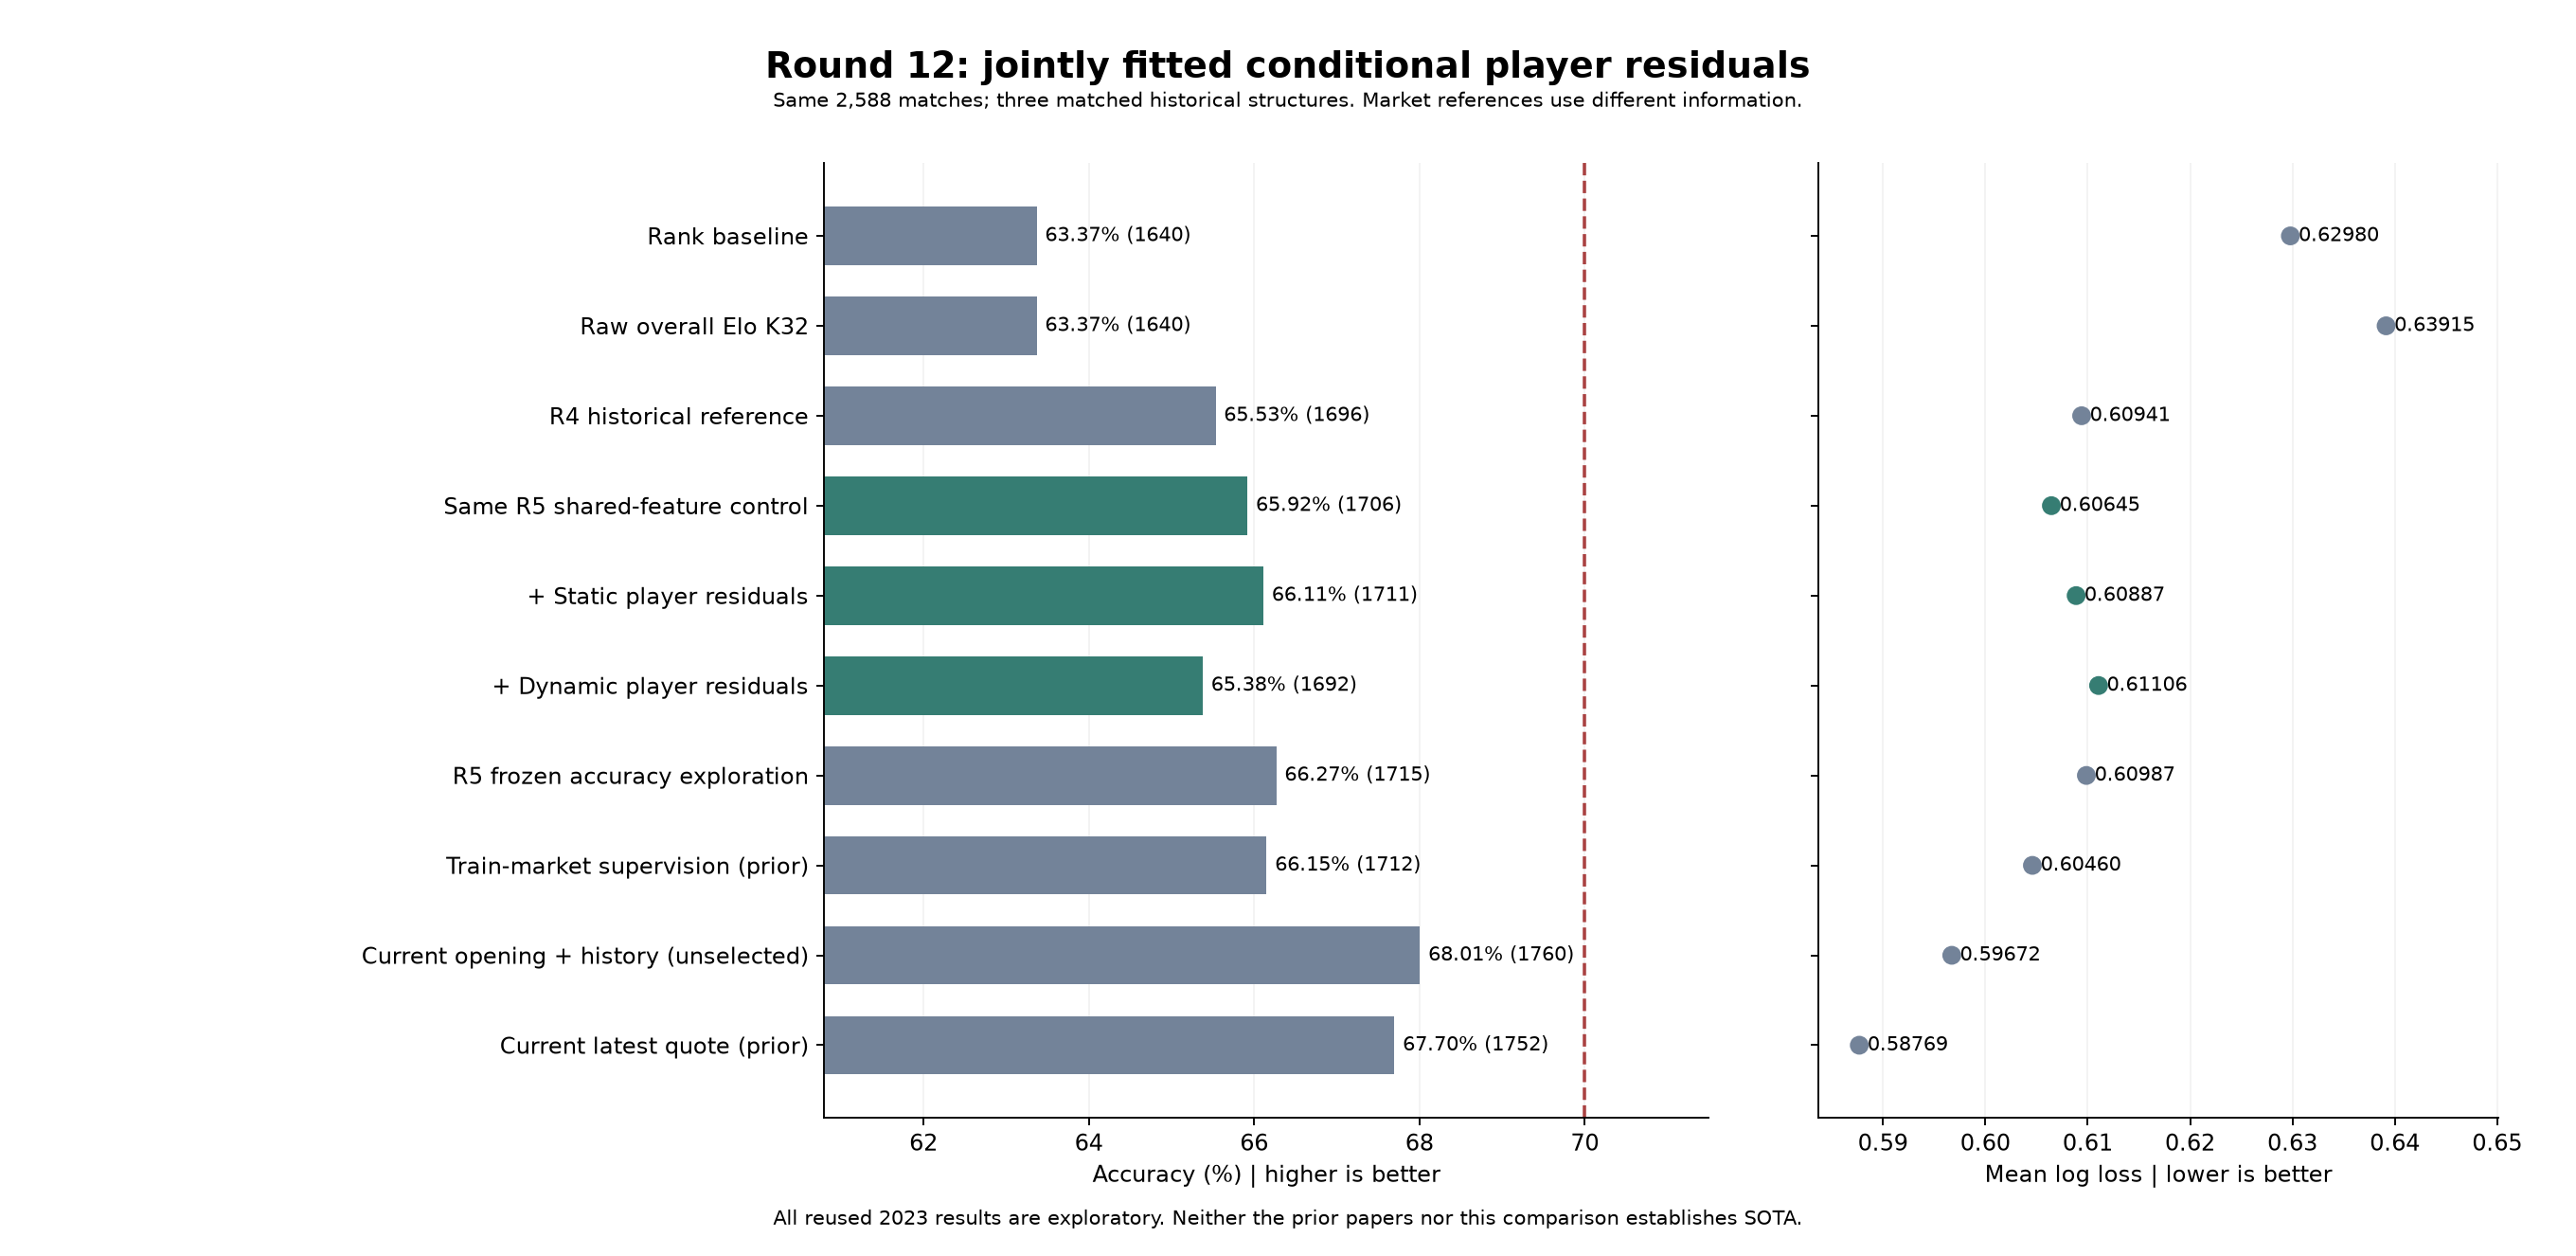

In [3]:
display(Image(filename=str(root/'results/round12/round12_comparison.png')))